# Optimización de hiperparámetros de la cabeza MIL (Multiple Instance Learning)

![Aruitectura](../img/arquiupdate.PNG)

**Qué se optimiza:** 
- Solo la etapa 2 (Transformer + attention pooling + MIL). 
- Los backbones (CLIP ViT-B/16 en apariencia,ConvNeXt-T en movimiento) están congelados y sus features ya están en disco, así que cada trial entrena solo la cabeza y tarda segundos o minutos.

**Diseño**

| Decisión | Elección | Justificación |
|---|---|---|
| Buscador | Optuna TPE, comparado con búsqueda aleatoria con el mismo presupuesto | TPE es bayesiano; el random da la línea de referencia |
| Poda | `MedianPruner` sobre el macro-F1 de validación por época | corta temprano los trials malos |
| Objetivo | Macro-F1 en validación (máximo sobre épocas, con early stopping) | es el mismo criterio con el que `vad train` elige checkpoint |
| Datos | train / val salen de Train; el test no se toca hasta el final y se usa una sola vez | evita el leakage de selección de modelo |
| Punto de partida | la config actual se encola como trial 0 (`default`) | para medir cuánto mejora la búsqueda |
| Robustez | top-K configs + `default` se reentrenan con varias semillas; t-test pareado vs `default` | val tiene ~98 videos y el F1 es ruidoso con una semilla |

Las λ del scorer de localización (`lambda_rank`, `lambda_normal`, `lambda_topk`,
`lambda_sparsity`, `lambda_score_smooth`, `rank_*`) y la arquitectura del scorer. Validación no tiene anotación
temporal, así que no hay una métrica limpia para tunearlas sin mirar el test. Igual se registran `sep(max)` y el score
medio de anómalos en cada trial para verificar que la búsqueda no rompe la localización.

In [ ]:
# ── Parámetros del sprint ────────────────────────────────────────────────────
CONFIG_PATH = "configs/hr320_clip_v2.yaml"   # config base (mejor variante: CLIP + diff)
N_TRIALS    = 50          # trials por estudio (TPE y random usan el mismo presupuesto)
MAX_EPOCHS  = None        # None = train.epochs del YAML (40);
TOP_K       = 3           # mejores configs que pasan a la prueba de robustez
SEEDS       = [42, 43, 44, 45, 46]
SAMPLER_SEED = 2026       # semilla del buscador (reproducibilidad del estudio)
SEP_TOLERANCE = 0.05      # la ganadora no puede bajar sep(max) más que esto vs default
RUN_FINAL_TRAIN = True    # reentrena la ganadora con run_train (guarda checkpoint en *_hpo)
RUN_TEST_EVAL   = True    # corre `vad evaluate` y `vad localize` UNA vez con la ganadora

In [4]:
import copy, json, logging, os, shutil, subprocess, sys, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
import yaml
from scipy import stats
from torch.utils.data import DataLoader

# Raíz del repo (el notebook vive en notebooks/)
ROOT = Path.cwd().resolve()
while not (ROOT / "configs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from vad.config import class_names, seed_everything
from vad.data.feature_dataset import BalancedBatchSampler, SegmentDataset
from vad.inference import build_model, get_device
from vad.train import _scores, evaluate_val, mil_losses, run_train

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)


def load_cfg(path):
    try:
        from vad.config import load_config
        return load_config(path)
    except (ImportError, TypeError):
        with open(path, encoding="utf-8") as f:
            return yaml.safe_load(f)


CONFIG_PATH = Path(CONFIG_PATH)
BASE_CFG = load_cfg(str(CONFIG_PATH))
if MAX_EPOCHS:
    BASE_CFG["train"]["epochs"] = int(MAX_EPOCHS)

HPO_DIR = ROOT / "artifacts" / "hpo" / CONFIG_PATH.stem
FIG_DIR = HPO_DIR / "figs"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = get_device()
NAMES = class_names(BASE_CFG)

print("Repo      :", ROOT)
print("Config    :", CONFIG_PATH)
print("Salidas   :", HPO_DIR.relative_to(ROOT))
print("Device    :", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Versiones : torch", torch.__version__, "| optuna", optuna.__version__)

e:\deepl\MIA\anomalia\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repo      : E:\deepl\MIA
Config    : configs\hr320_clip_v2.yaml
Salidas   : artifacts\hpo\hr320_clip_v2
Device    : cuda | NVIDIA GeForce RTX 5070 Ti
Versiones : torch 2.11.0+cu128 | optuna 5.0.0


## 1. Datos (se cargan una sola vez para todos los trials)

In [5]:
t0 = time.time()
TRAIN_DS = SegmentDataset(BASE_CFG, "train")
VAL_DS = SegmentDataset(BASE_CFG, "val")
print(f"Features cargadas en {time.time() - t0:.1f} s")
pd.DataFrame({
    "train": np.bincount(TRAIN_DS.labels, minlength=len(NAMES)),
    "val": np.bincount(VAL_DS.labels, minlength=len(NAMES)),
}, index=NAMES)

Features cargadas en 12.7 s


,train,val
Normal,160,40
Aggression,110,28
Theft,120,30


## 2. Espacio de búsqueda

| Hiperparámetro | Sección | Rango | Default |
|---|---|---|---|
| `lr` | train | 1e-5 – 1e-3 (log) | 3e-4 |
| `weight_decay` | train | 1e-4 – 1e-1 (log) | 1e-2 |
| `batch_size` | train | {16, 32, 64} | 32 |
| `d_model` | model | {256, 512} | 512 |
| `nhead` | model | {4, 8} | 8 |
| `num_layers` | model | 1 – 4 | 2 |
| `dropout` | model | 0.0 – 0.5 | 0.3 |
| `attn_temp` | model | 0.25 – 1.0 | 0.5 |
| `lambda_ent` | train | 0.0 – 1.0 | 0.3 |
| `lambda_seg` | train | 0.0 – 1.0 | 0.5 |
| `lambda_smooth` | train | 0.0 – 0.5 | 0.1 |

In [6]:
PARAM_SECTION = {
    "lr": "train", "weight_decay": "train", "batch_size": "train",
    "lambda_ent": "train", "lambda_seg": "train", "lambda_smooth": "train",
    "d_model": "model", "nhead": "model", "num_layers": "model", "dropout": "model", "attn_temp": "model",
}
INT_PARAMS = {"batch_size", "d_model", "nhead", "num_layers"}


def sample_params(trial: optuna.Trial) -> dict:
    return {
        "lr": trial.suggest_float("lr", 1e-5, 1e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-4, 1e-1, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32, 64]),
        "d_model": trial.suggest_categorical("d_model", [256, 512]),
        "nhead": trial.suggest_categorical("nhead", [4, 8]),
        "num_layers": trial.suggest_int("num_layers", 1, 4),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "attn_temp": trial.suggest_float("attn_temp", 0.25, 1.0),
        "lambda_ent": trial.suggest_float("lambda_ent", 0.0, 1.0),
        "lambda_seg": trial.suggest_float("lambda_seg", 0.0, 1.0),
        "lambda_smooth": trial.suggest_float("lambda_smooth", 0.0, 0.5),
    }


def apply_params(cfg: dict, params: dict) -> dict:
    out = copy.deepcopy(cfg)
    for k, v in params.items():
        out[PARAM_SECTION[k]][k] = int(v) if k in INT_PARAMS else float(v)
    return out


DEFAULT_PARAMS = {k: BASE_CFG[sec][k] for k, sec in PARAM_SECTION.items()}
DEFAULT_PARAMS = {k: (int(v) if k in INT_PARAMS else float(v)) for k, v in DEFAULT_PARAMS.items()}
DEFAULT_PARAMS

{'lr': 0.0003,
 'weight_decay': 0.01,
 'batch_size': 32,
 'lambda_ent': 0.3,
 'lambda_seg': 0.5,
 'lambda_smooth': 0.1,
 'd_model': 512,
 'nhead': 8,
 'num_layers': 2,
 'dropout': 0.3,
 'attn_temp': 0.5}

## 3. Función objetivo

`train_eval` replica el loop de `vad.train.run_train` (mismas pérdidas `mil_losses`, mismos pesos de clase, AdamW +
cosine, clipping 1.0, early stopping por macro-F1 en val), pero sin guardar checkpoints y reportando a Optuna en
cada época para poder podar.

In [7]:
def train_eval(cfg: dict, seed: int, trial: optuna.Trial | None = None) -> dict:
    tc = cfg["train"]
    seed_everything(seed)
    train_loader = DataLoader(TRAIN_DS, batch_sampler=BalancedBatchSampler(TRAIN_DS.labels, tc["batch_size"], seed),
                              num_workers=0)
    val_loader = DataLoader(VAL_DS, batch_size=tc["batch_size"], shuffle=False, num_workers=0)
    counts = np.bincount(TRAIN_DS.labels, minlength=len(NAMES)).astype(float)
    class_w = torch.tensor(counts.sum() / (len(NAMES) * np.maximum(counts, 1)), dtype=torch.float32)

    model = build_model(cfg, DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=tc["lr"], weight_decay=tc["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=tc["epochs"])
    criterion = nn.CrossEntropyLoss(weight=class_w.to(DEVICE))

    best, no_improve = {"f1": -1.0, "epoch": 0}, 0
    try:
        for epoch in range(1, tc["epochs"] + 1):
            model.train()
            for rgb, mot, y, _, rgb_s, mot_s in train_loader:
                rgb, mot, y = rgb.to(DEVICE), mot.to(DEVICE), y.to(DEVICE)
                out = model(rgb, mot)
                s = _scores(model, out, rgb_s, mot_s, DEVICE)
                parts = {"ce": criterion(out["video_logits"].float(), y), **mil_losses(out, s, y, tc)}
                loss = sum(parts.values())
                if not torch.isfinite(loss):
                    if trial is not None:
                        raise optuna.TrialPruned(f"pérdida no finita en época {epoch}")
                    return {**best, "diverged": True}
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            scheduler.step()

            val = evaluate_val(model, val_loader, criterion, DEVICE)
            if val["f1"] > best["f1"]:
                best = {k: v for k, v in val.items() if k != "pred_dist"}
                best["epoch"], no_improve = epoch, 0
            else:
                no_improve += 1
            if trial is not None:
                trial.report(best["f1"], epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
            if no_improve >= tc["patience"]:
                break
    finally:
        del model, optimizer
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return best


def objective(trial: optuna.Trial) -> float:
    t0 = time.time()
    params = sample_params(trial)
    best = train_eval(apply_params(BASE_CFG, params), BASE_CFG["train"]["seed"], trial)
    for k in ("acc", "score_separation", "mean_score_anom", "mean_score_norm", "epoch"):
        trial.set_user_attr(k, best.get(k))
    trial.set_user_attr("secs", round(time.time() - t0, 1))
    return best["f1"]


# Prueba rápida: la config default con la semilla base (debe parecerse a tu val F1 de `vad train`)
t0 = time.time()
ref = train_eval(apply_params(BASE_CFG, DEFAULT_PARAMS), BASE_CFG["train"]["seed"])
print(f"default → val macro-F1 {ref['f1']:.4f} | época {ref['epoch']} | sep(max) {ref['score_separation']:.3f} "
      f"| {time.time() - t0:.1f} s por trial (sin poda)")

default → val macro-F1 0.7646 | época 2 | sep(max) 0.632 | 13.4 s por trial (sin poda)


## 4. Estudios: TPE vs búsqueda aleatoria (mismo presupuesto)

In [8]:
STORAGE = f"sqlite:///{(HPO_DIR / 'optuna.db').as_posix()}"   # se puede pausar y retomar


def run_study(kind: str) -> optuna.Study:
    sampler = (optuna.samplers.TPESampler(seed=SAMPLER_SEED, n_startup_trials=10, multivariate=True)
               if kind == "tpe" else optuna.samplers.RandomSampler(seed=SAMPLER_SEED + 1))
    pruner = optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=10)
    study = optuna.create_study(study_name=f"{CONFIG_PATH.stem}_{kind}", storage=STORAGE, direction="maximize",
                                sampler=sampler, pruner=pruner, load_if_exists=True)
    if len(study.trials) == 0:
        study.enqueue_trial(DEFAULT_PARAMS, user_attrs={"default": True})
    finished = sum(t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED) for t in study.trials)
    remaining = N_TRIALS - finished
    print(f"[{kind}] {finished} trials previos → faltan {max(remaining, 0)}")
    if remaining > 0:
        t0 = time.time()
        study.optimize(objective, n_trials=remaining, gc_after_trial=True, show_progress_bar=True)
        print(f"[{kind}] {time.time() - t0:.0f} s")
    return study


studies = {"tpe": run_study("tpe"), "random": run_study("random")}

[tpe] 0 trials previos → faltan 50


Best trial: 22. Best value: 0.82215: 100%|██████████| 50/50 [05:55<00:00,  7.11s/it] 


[tpe] 355 s
[random] 0 trials previos → faltan 50


Best trial: 12. Best value: 0.79487: 100%|██████████| 50/50 [05:24<00:00,  6.48s/it]

[random] 324 s


## 5. Resultados

In [9]:
def trials_df(study: optuna.Study, kind: str) -> pd.DataFrame:
    df = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs", "duration"))
    df = df.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
    df["study"] = kind
    df["default"] = df["default"].fillna(False).astype(bool) if "default" in df else False
    df["duration_s"] = df["duration"].dt.total_seconds().round(1)
    return df.drop(columns="duration")


DF = pd.concat([trials_df(s, k) for k, s in studies.items()], ignore_index=True)
DF.to_csv(HPO_DIR / "trials.csv", index=False, encoding="utf-8-sig")
COMPLETE = DF[DF["state"] == "COMPLETE"].copy()

default_f1 = float(COMPLETE.loc[COMPLETE["default"], "value"].mean())
resumen = pd.DataFrame([{
    "estudio": k,
    "trials": int((DF["study"] == k).sum()),
    "completos": int(((DF["study"] == k) & (DF["state"] == "COMPLETE")).sum()),
    "podados": int(((DF["study"] == k) & (DF["state"] == "PRUNED")).sum()),
    "mejor val F1": s.best_value,
    "trial del mejor": s.best_trial.number,
    "mejora vs default": s.best_value - default_f1,
    "tiempo total (min)": round(DF.loc[DF["study"] == k, "duration_s"].sum() / 60, 1),
} for k, s in studies.items()]).set_index("estudio")
print(f"default (trial 0): val macro-F1 {default_f1:.4f}")
resumen.round(4)

default (trial 0): val macro-F1 0.7646


,trials,completos,podados,mejor val F1,trial del mejor,mejora vs default,tiempo total (min)
estudio,,,,,,,
tpe,50,23,27,0.8222,22,0.0575,5.8
random,50,21,29,0.7949,12,0.0303,5.3


In [10]:
cols = ["study", "number", "value", "score_separation", "mean_score_anom", "epoch"] + list(PARAM_SECTION)
COMPLETE.sort_values("value", ascending=False)[cols].head(10).round(4)

,study,number,value,score_separation,mean_score_anom,epoch,lr,weight_decay,batch_size,lambda_ent,lambda_seg,lambda_smooth,d_model,nhead,num_layers,dropout,attn_temp
22,tpe,22,0.8222,0.6835,0.6556,7.0,0.0001,0.0015,32,0.7095,0.5041,0.1411,256,8,4,0.0474,0.6816
40,tpe,40,0.8125,0.7787,0.5372,13.0,0.0001,0.0018,32,0.8257,0.5240,0.1797,256,8,4,0.3622,0.5757
23,tpe,23,0.8109,0.7762,0.5693,20.0,0.0001,0.0070,32,0.7158,0.4936,0.2891,256,8,4,0.2647,0.5203
38,tpe,38,0.8105,0.7765,0.5595,9.0,0.0002,0.0164,32,0.7929,0.5920,0.2531,256,8,4,0.2417,0.5072
15,tpe,15,0.8088,0.7295,0.6309,9.0,0.0001,0.0066,32,0.8649,0.5098,0.2371,256,8,4,0.2312,0.4968
32,tpe,32,0.8009,0.7254,0.6531,8.0,0.0002,0.0025,32,0.7005,0.3959,0.3127,256,8,4,0.0824,0.6624
35,tpe,35,0.8001,0.7390,0.6037,10.0,0.0001,0.0077,32,0.9047,0.4158,0.3464,256,8,4,0.1971,0.5194
9,tpe,9,0.7992,0.7647,0.6015,8.0,0.0002,0.0056,32,0.7794,0.7869,0.2884,256,8,4,0.0932,0.6131
62,random,12,0.7949,0.7156,0.6737,7.0,0.0003,0.0231,64,0.3149,0.2589,0.0507,256,4,4,0.3613,0.9156
14,tpe,14,0.7904,0.6178,0.6358,7.0,0.0000,0.0039,32,0.5246,0.4451,0.1506,256,8,4,0.0870,0.5882


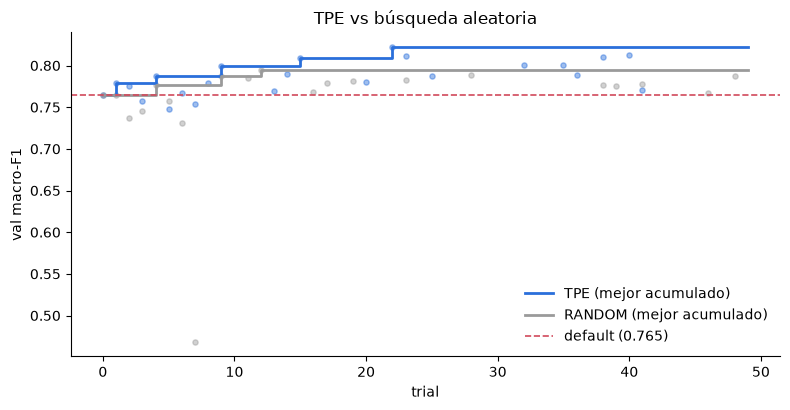

In [11]:
# Convergencia: mejor F1 acumulado por número de trial
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, color in (("tpe", "#2a6fdb"), ("random", "#9a9a9a")):
    d = DF[DF["study"] == k].sort_values("number")
    vals = d["value"].where(d["state"] == "COMPLETE")
    ax.scatter(d["number"], vals, s=14, color=color, alpha=0.45)
    ax.step(d["number"], vals.ffill().cummax(), where="post", color=color, lw=2, label=f"{k.upper()} (mejor acumulado)")
ax.axhline(default_f1, ls="--", color="#d1495b", lw=1.2, label=f"default ({default_f1:.3f})")
ax.set(xlabel="trial", ylabel="val macro-F1", title="TPE vs búsqueda aleatoria")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "convergencia.png", dpi=150); plt.show()

### Importancia de hiperparámetros

fANOVA sobre los trials completos de TPE: qué fracción de la varianza del F1 explica cada hiperparámetro. Se complementa
con el sprint de importancia de variables (allí era importancia de las features, aquí de la configuración de entrenamiento).

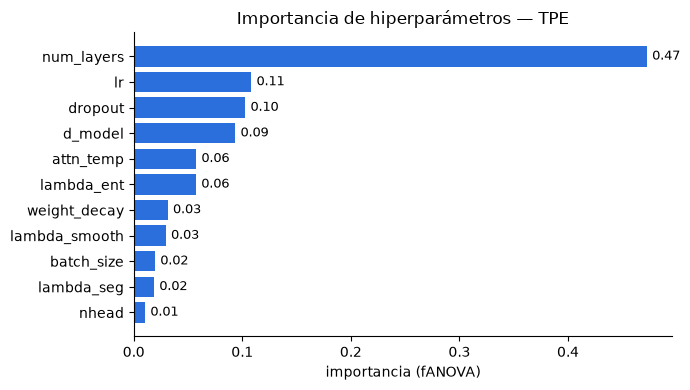

,importancia
num_layers,0.473
lr,0.108
dropout,0.103
d_model,0.093
attn_temp,0.057
lambda_ent,0.057
weight_decay,0.031
lambda_smooth,0.029
batch_size,0.019
lambda_seg,0.019


In [12]:
try:
    imp = optuna.importance.get_param_importances(
        studies["tpe"], evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SAMPLER_SEED))
except Exception as e:  # pocos trials completos, etc.
    print("fANOVA no disponible:", e)
    imp = {}
IMP = pd.Series(imp, name="importancia").sort_values()
if len(IMP):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(IMP.index, IMP.values, color="#2a6fdb")
    for i, v in enumerate(IMP.values):
        ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9)
    ax.set(xlabel="importancia (fANOVA)", title="Importancia de hiperparámetros — TPE")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); fig.savefig(FIG_DIR / "importancia_hiperparametros.png", dpi=150); plt.show()
IMP.sort_values(ascending=False).round(3).to_frame()

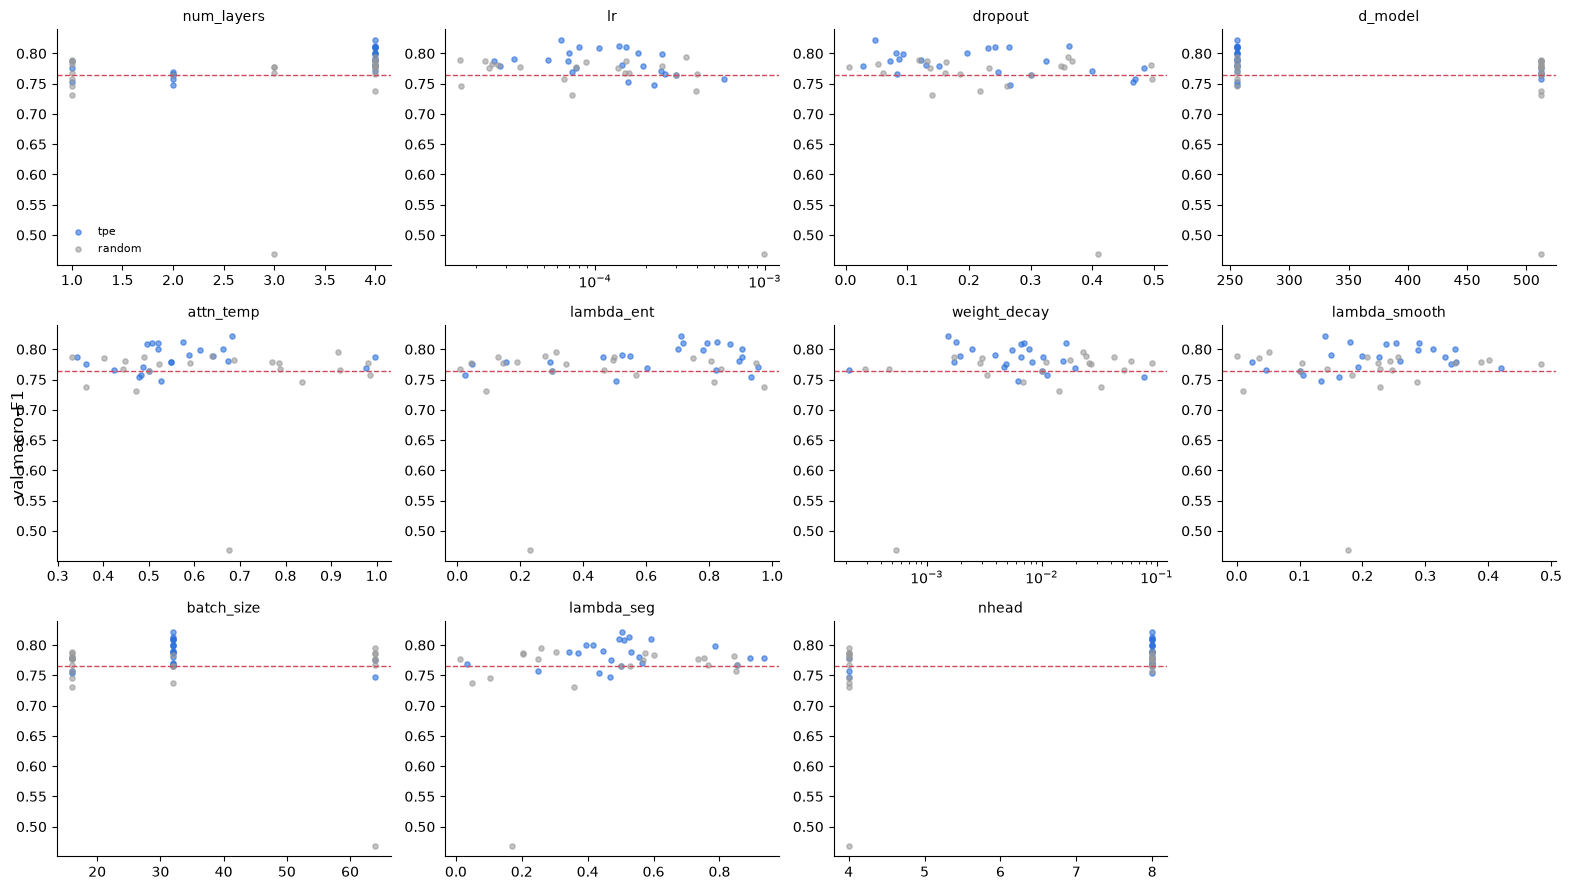

In [13]:
# Slice plots: valor de cada hiperparámetro vs val F1 (todos los trials completos de ambos estudios)
params = list(IMP.sort_values(ascending=False).index) if len(IMP) else list(PARAM_SECTION)
n = len(params); ncols = 4; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)
for ax, p in zip(axes.flat, params):
    for k, color in (("tpe", "#2a6fdb"), ("random", "#9a9a9a")):
        d = COMPLETE[COMPLETE["study"] == k]
        ax.scatter(d[p], d["value"], s=14, alpha=0.6, color=color, label=k)
    ax.axhline(default_f1, ls="--", color="#d1495b", lw=1)
    if p in ("lr", "weight_decay"):
        ax.set_xscale("log")
    ax.set_title(p, fontsize=10); ax.spines[["top", "right"]].set_visible(False)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.supylabel("val macro-F1")
fig.tight_layout(); fig.savefig(FIG_DIR / "slice_plots.png", dpi=150); plt.show()

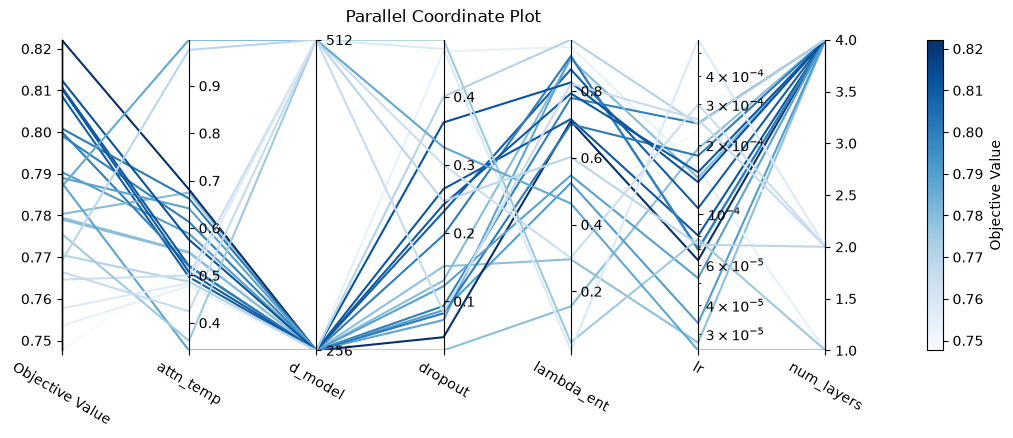

In [14]:
try:
    ax = optuna.visualization.matplotlib.plot_parallel_coordinate(
        studies["tpe"], params=list(IMP.sort_values(ascending=False).index[:6]) or None)
    fig = ax.figure if hasattr(ax, "figure") else plt.gcf()
    fig.set_size_inches(11, 4.5); fig.tight_layout(); fig.savefig(FIG_DIR / "coordenadas_paralelas.png", dpi=150)
    plt.show()
except Exception as e:
    print("Coordenadas paralelas no disponibles:", e)

### Chequeo de localización

El objetivo es F1 de clasificación, pero el scorer se entrena en el mismo loop. Un buen trial no debería empeorar la
separación de scores (`sep(max)` alto) ni marcar todo el video (`score medio anómalos` debe quedar bajo).

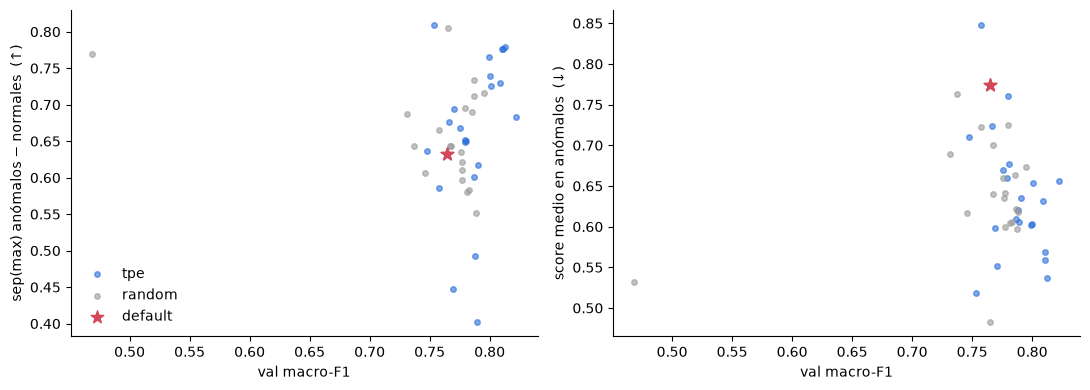

Correlación F1 vs sep(max): -0.096


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, lab in ((axes[0], "score_separation", "sep(max) anómalos − normales  (↑)"),
                     (axes[1], "mean_score_anom", "score medio en anómalos  (↓)")):
    for k, color in (("tpe", "#2a6fdb"), ("random", "#9a9a9a")):
        d = COMPLETE[COMPLETE["study"] == k]
        ax.scatter(d["value"], d[col], s=16, alpha=0.6, color=color, label=k)
    d0 = COMPLETE[COMPLETE["default"]]
    ax.scatter(d0["value"], d0[col], s=90, marker="*", color="#d1495b", label="default", zorder=3)
    ax.set(xlabel="val macro-F1", ylabel=lab); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "chequeo_localizacion.png", dpi=150); plt.show()
print("Correlación F1 vs sep(max):", round(COMPLETE[["value", "score_separation"]].corr().iloc[0, 1], 3))

## 6. Robustez: top-K vs default con varias semillas

El F1 de un trial depende de la semilla. Las mejores configs se reentrenan con `SEEDS` y se comparan contra `default`
con un **t-test pareado** (misma semilla = mismo orden de batches e inicialización). Con 5 semillas el Wilcoxon no
puede bajar de p = 0.0625, por eso se reporta el t-test como prueba principal.

Los resultados se guardan en `robustez_raw.csv`; si reejecutas el notebook, no se repiten corridas ya hechas.

In [16]:
def key(params):
    return json.dumps({k: round(float(v), 8) for k, v in sorted(params.items())})


ranked = COMPLETE[~COMPLETE["default"]].sort_values("value", ascending=False)
CANDIDATES, seen = {"default": DEFAULT_PARAMS}, {key(DEFAULT_PARAMS)}
for _, r in ranked.iterrows():
    p = {k: (int(r[k]) if k in INT_PARAMS else float(r[k])) for k in PARAM_SECTION}
    if key(p) in seen:
        continue
    seen.add(key(p)); CANDIDATES[f"{r['study'].upper()}#{int(r['number'])}"] = p
    if len(CANDIDATES) > TOP_K:
        break

RAW_PATH = HPO_DIR / "robustez_raw.csv"
raw = pd.read_csv(RAW_PATH) if RAW_PATH.exists() else pd.DataFrame(columns=["params_key", "seed"])
rows = raw.to_dict("records")
done = {(r["params_key"], int(r["seed"])) for r in rows}
total = len(CANDIDATES) * len(SEEDS); t0 = time.time()
for name, p in CANDIDATES.items():
    for seed in SEEDS:
        if (key(p), seed) in done:
            continue
        b = train_eval(apply_params(BASE_CFG, p), seed)
        rows.append({"candidato": name, "params_key": key(p), "seed": seed, "f1": b["f1"], "acc": b.get("acc"),
                     "score_separation": b.get("score_separation"), "mean_score_anom": b.get("mean_score_anom"),
                     "epoch": b["epoch"]})
        pd.DataFrame(rows).to_csv(RAW_PATH, index=False)
        print(f"  {name:<12} seed {seed} → F1 {b['f1']:.4f}  ({len(rows)}/{total}, {time.time() - t0:.0f} s)")
RAW = pd.DataFrame(rows)
RAW = RAW[RAW["params_key"].isin([key(p) for p in CANDIDATES.values()])].copy()
RAW["candidato"] = RAW["params_key"].map({key(p): n for n, p in CANDIDATES.items()})

  default      seed 42 → F1 0.7646  (1/20, 4 s)
  default      seed 43 → F1 0.7776  (2/20, 11 s)
  default      seed 44 → F1 0.7726  (3/20, 18 s)
  default      seed 45 → F1 0.7557  (4/20, 23 s)
  default      seed 46 → F1 0.7422  (5/20, 28 s)
  TPE#22       seed 42 → F1 0.8222  (6/20, 36 s)
  TPE#22       seed 43 → F1 0.7537  (7/20, 43 s)
  TPE#22       seed 44 → F1 0.7566  (8/20, 56 s)
  TPE#22       seed 45 → F1 0.7174  (9/20, 62 s)
  TPE#22       seed 46 → F1 0.8059  (10/20, 67 s)
  TPE#40       seed 42 → F1 0.8125  (11/20, 78 s)
  TPE#40       seed 43 → F1 0.7941  (12/20, 85 s)
  TPE#40       seed 44 → F1 0.7653  (13/20, 95 s)
  TPE#40       seed 45 → F1 0.7416  (14/20, 106 s)
  TPE#40       seed 46 → F1 0.7848  (15/20, 114 s)
  TPE#23       seed 42 → F1 0.8109  (16/20, 128 s)
  TPE#23       seed 43 → F1 0.7910  (17/20, 138 s)
  TPE#23       seed 44 → F1 0.7608  (18/20, 143 s)
  TPE#23       seed 45 → F1 0.7565  (19/20, 151 s)
  TPE#23       seed 46 → F1 0.7939  (20/20, 157 s)


In [17]:
base = RAW[RAW["candidato"] == "default"].set_index("seed")
summary = []
for name in CANDIDATES:
    d = RAW[RAW["candidato"] == name].set_index("seed")
    common = d.index.intersection(base.index)
    row = {"candidato": name, "F1 media": d["f1"].mean(), "F1 std": d["f1"].std(ddof=1),
           "sep(max) media": d["score_separation"].mean(), "score anóm. media": d["mean_score_anom"].mean(),
           "Δ F1 vs default": d["f1"].mean() - base["f1"].mean(), "p (t pareado)": np.nan, "p (Wilcoxon)": np.nan}
    if name != "default" and len(common) >= 2:
        diff = d.loc[common, "f1"] - base.loc[common, "f1"]
        if diff.abs().sum() > 0:
            row["p (t pareado)"] = stats.ttest_rel(d.loc[common, "f1"], base.loc[common, "f1"]).pvalue
            try:
                row["p (Wilcoxon)"] = stats.wilcoxon(diff).pvalue
            except ValueError:
                pass
    summary.append(row)
SUMMARY = pd.DataFrame(summary).set_index("candidato")

# Regla de selección: mayor F1 medio entre los que no empeoran sep(max) más que SEP_TOLERANCE
sep_min = SUMMARY.loc["default", "sep(max) media"] - SEP_TOLERANCE
eligible = SUMMARY[SUMMARY["sep(max) media"] >= sep_min]
WINNER = eligible["F1 media"].idxmax() if len(eligible) else "default"
WINNER_PARAMS = CANDIDATES[WINNER]
w = SUMMARY.loc[WINNER]
SIGNIFICANT = bool(WINNER != "default" and w["p (t pareado)"] < 0.05 and w["Δ F1 vs default"] > 0)
print(f"Ganadora: {WINNER} | F1 {w['F1 media']:.4f} ± {w['F1 std']:.4f} | Δ {w['Δ F1 vs default']:+.4f} | "
      f"p {w['p (t pareado)']:.4f} → {'mejora significativa' if SIGNIFICANT else 'sin diferencia significativa vs default'}")
SUMMARY.round(4)

Ganadora: TPE#23 | F1 0.7826 ± 0.0232 | Δ +0.0201 | p 0.1828 → sin diferencia significativa vs default


,F1 media,F1 std,sep(max) media,score anóm. media,Δ F1 vs default,p (t pareado),p (Wilcoxon)
candidato,,,,,,,
default,0.7625,0.0141,0.6933,0.6701,0.0000,NaN,NaN
TPE#22,0.7711,0.0425,0.6244,0.6548,0.0086,0.7105,0.8125
TPE#40,0.7797,0.0272,0.7267,0.6262,0.0171,0.2453,0.3125
TPE#23,0.7826,0.0232,0.6897,0.6309,0.0201,0.1828,0.1875


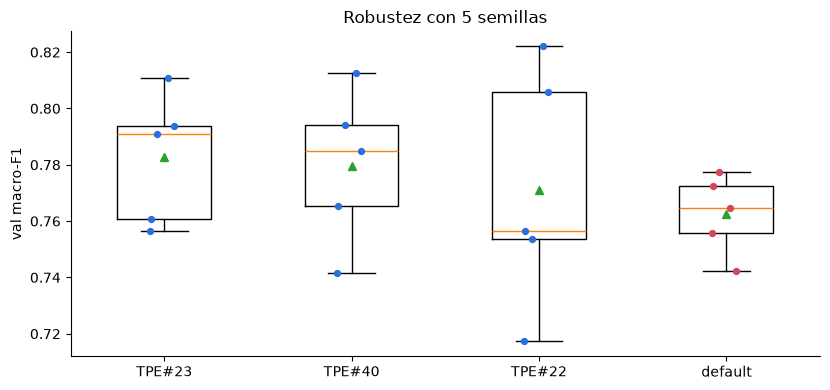

In [18]:
order = list(SUMMARY.sort_values("F1 media", ascending=False).index)
fig, ax = plt.subplots(figsize=(1.6 * len(order) + 2, 4))
data = [RAW.loc[RAW["candidato"] == c, "f1"].values for c in order]
ax.boxplot(data, widths=0.5, showmeans=True)
ax.set_xticks(range(1, len(order) + 1), order)
for i, c in enumerate(order, 1):
    ax.scatter(np.full(len(data[i - 1]), i) + np.random.default_rng(0).uniform(-.08, .08, len(data[i - 1])),
               data[i - 1], s=18, color="#d1495b" if c == "default" else "#2a6fdb", zorder=3)
ax.set(ylabel="val macro-F1", title=f"Robustez con {len(SEEDS)} semillas")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "robustez_semillas.png", dpi=150); plt.show()

## 7. Exportar la configuración ganadora

In [19]:
HPO_CFG_PATH = CONFIG_PATH.with_name(f"{CONFIG_PATH.stem}_hpo.yaml")
changes = {k: (DEFAULT_PARAMS[k], v) for k, v in WINNER_PARAMS.items() if not np.isclose(DEFAULT_PARAMS[k], v)}
(HPO_DIR / "best_params.json").write_text(json.dumps(
    {"winner": WINNER, "params": WINNER_PARAMS, "significant_vs_default": SIGNIFICANT,
     "summary": SUMMARY.reset_index().to_dict("records")}, indent=2, default=float), encoding="utf-8")

if WINNER == "default":
    print("La config actual sigue siendo la mejor: no se genera un YAML nuevo.")
    FINAL_CFG_PATH = CONFIG_PATH
else:
    best_cfg = apply_params(load_cfg(str(CONFIG_PATH)), WINNER_PARAMS)
    best_cfg["paths"]["checkpoints_dir"] = BASE_CFG["paths"]["checkpoints_dir"] + "_hpo"
    best_cfg["paths"]["reports_dir"] = BASE_CFG["paths"]["reports_dir"] + "_hpo"
    header = [f"# Generado por notebooks/05_optimizacion_hiperparametros.ipynb ({time.strftime('%Y-%m-%d')})",
              f"# Base: {CONFIG_PATH.as_posix()} | ganadora: {WINNER} | estudio: artifacts/hpo/{CONFIG_PATH.stem}/",
              "# Cambios respecto a la base:"]
    header += [f"#   {PARAM_SECTION[k]}.{k}: {a} → {b:.6g}" for k, (a, b) in changes.items()]
    with open(HPO_CFG_PATH, "w", encoding="utf-8") as f:
        f.write("\n".join(header) + "\n\n")
        yaml.safe_dump(best_cfg, f, sort_keys=False, allow_unicode=True)
    FINAL_CFG_PATH = HPO_CFG_PATH
    print("Config escrita en", HPO_CFG_PATH.as_posix())
pd.DataFrame(changes, index=["default", "ganadora"]).T

Config escrita en configs/hr320_clip_v2_hpo.yaml


,default,ganadora
lr,0.0003,0.000080
weight_decay,0.0100,0.006962
lambda_ent,0.3000,0.715808
lambda_seg,0.5000,0.493588
lambda_smooth,0.1000,0.289145
d_model,512.0000,256.000000
num_layers,2.0000,4.000000
dropout,0.3000,0.264659
attn_temp,0.5000,0.520265


## 8. Entrenamiento final y evaluación en test (una sola vez)

Se reentrena la ganadora con `run_train` (el mismo código de `vad train`, guarda el checkpoint en `*_hpo`) y luego se
corre `vad evaluate` y `vad localize` con esa config.

In [20]:
if RUN_FINAL_TRAIN and WINNER != "default":
    logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(message)s", datefmt="%H:%M:%S", force=True)
    FINAL = run_train(load_cfg(str(FINAL_CFG_PATH)))
    logging.getLogger().setLevel(logging.WARNING)
    print(FINAL)
else:
    FINAL = None
    print("Entrenamiento final omitido.")

18:04:06 | ======================================================================
18:04:06 | ENTRENAMIENTO MIL | cuda | snippet=3 frames | 32 segmentos (Transformer) / 128 (scorer) | top-k 0.1·T | seed 42
18:04:06 | λ: {'lambda_ent': 0.7158081073248369, 'lambda_seg': 0.4935876789858519, 'lambda_smooth': 0.28914494272960517, 'lambda_rank': 1.0, 'rank_margin': 1.0, 'rank_topk': 3, 'rank_topk_ratio': 0.1, 'lambda_normal': 1.0, 'lambda_topk': 1.0, 'lambda_sparsity': 0.1, 'lambda_score_smooth': 0.1}
18:04:06 | ======================================================================
18:04:06 | Cargando features...
18:04:14 |   train: 390 videos | dist {0: 160, 1: 110, 2: 120} | 32 segmentos (Transformer) / 128 (scorer) | snippets/video mediana 87
18:04:16 |   val: 98 videos | dist {0: 40, 1: 28, 2: 30} | 32 segmentos (Transformer) / 128 (scorer) | snippets/video mediana 85
18:04:16 | Pesos CE por clase: {'Normal': 0.8119999766349792, 'Aggression': 1.1820000410079956, 'Theft': 1.082999944686889

{'best_val_f1': 0.8108585858585858, 'best_epoch': 20}


In [21]:
TEST_LOG = []
if RUN_TEST_EVAL and FINAL is not None:
    vad_bin = shutil.which("vad")
    if vad_bin is None:
        print("No encuentro el comando `vad` en este kernel. Córrelo en la terminal del entorno:")
        print(f"  vad --config {FINAL_CFG_PATH.as_posix()} evaluate")
        print(f"  vad --config {FINAL_CFG_PATH.as_posix()} localize --plot-all")
    else:
        for cmd in (["evaluate"], ["localize", "--plot-all"]):
            r = subprocess.run([vad_bin, "--config", FINAL_CFG_PATH.as_posix(), *cmd],
                               capture_output=True, text=True, encoding="utf-8", errors="replace")
            out = (r.stdout + r.stderr).strip().splitlines()
            keep = [l for l in out if any(t in l for t in ("Video", "Binario", "Frame", "tIoU", "F1", "ERROR"))]
            TEST_LOG += keep
            print(f"$ vad --config {FINAL_CFG_PATH.as_posix()} {' '.join(cmd)}  (exit {r.returncode})")
            print("\n".join(keep or out[-15:]), "\n")

$ vad --config configs/hr320_clip_v2_hpo.yaml evaluate  (exit 0)
18:04:55 | INFO    | Checkpoint artifacts\checkpoints_320_clip_v2_hpo\best_model.pth | época 20 | val macro-F1 0.8109 | score_head=local
18:05:00 | INFO    | Video  | acc 0.8818 | macro-F1 0.7323 | macro AUC 0.9427
18:05:00 | INFO    |   Normal        P 0.929  R 0.953  F1 0.941
18:05:00 | INFO    |   Aggression    P 0.500  R 0.500  F1 0.500
18:05:00 | INFO    |   Theft         P 0.795  R 0.721  F1 0.756
18:05:00 | INFO    | Binario (normal vs anómalo) | acc 0.9113 | recall anomalía 0.792 | especificidad 0.953 | AUC(1-P normal) 0.9321 | AUC(max score) 0.9223
18:05:00 | INFO    | Frame  | AUC 0.9059 | AP 0.4109 | AUC solo anómalos 0.6993 | 870,440 frames 

$ vad --config configs/hr320_clip_v2_hpo.yaml localize --plot-all  (exit 0)
18:05:03 | INFO    | Checkpoint artifacts\checkpoints_320_clip_v2_hpo\best_model.pth | época 20 | val macro-F1 0.8109 | score_head=local
18:05:12 | INFO    | tIoU medio 0.2574631849876485 | videos